In [1]:
import requests
import pandas as pd
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

In [2]:
url = "https://books.toscrape.com/index.html"

response = requests.get(url, timeout=30)

print("Status code:", response.status_code)
print("Website response:", response.reason)

Status code: 200
Website response: OK


In [3]:
soup = BeautifulSoup(response.content, "html.parser")

print(soup.title.get_text(strip=True))

All products | Books to Scrape - Sandbox


In [4]:
books = soup.select("article.product_pod")

print("Number of books on this page:", len(books))

Number of books on this page: 20


In [7]:
def scrape_books_from_page(soup, page_number, page_url):
    books_data = []

    for book in soup.select("article.product_pod"):
        title = book.select_one("h3 a")["title"]

        price_text = book.select_one(
            "p.price_color"
        ).get_text(strip=True)

        price = float(
            price_text.replace("£", "").replace("Â", "")
        )

        rating = book.select_one(
            "p.star-rating"
        )["class"][1]

        availability = book.select_one(
            "p.availability"
        ).get_text(" ", strip=True)

        book_url = urljoin(
            page_url,
            book.select_one("h3 a")["href"]
        )

        image_url = urljoin(
            page_url,
            book.select_one("div.image_container img")["src"]
        )

        books_data.append({
            "Page": page_number,
            "Title": title,
            "Price (£)": price,
            "Rating": rating,
            "Availability": availability,
            "Book URL": book_url,
            "Image URL": image_url
        })

    return books_data

In [8]:
start_url = "https://books.toscrape.com/index.html"

all_books = []
page_number = 1
current_url = start_url

while current_url:
    print(f"Scraping page {page_number}: {current_url}")

    response = requests.get(current_url, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.content, "html.parser")

    page_books = scrape_books_from_page(
        soup, page_number, current_url
    )

    all_books.extend(page_books)

    print(
        f"Books collected on this page: {len(page_books)}"
    )
    print(f"Total books collected: {len(all_books)}")

    next_link = soup.select_one("li.next a")

    if next_link:
        current_url = urljoin(
            current_url, next_link["href"]
        )
        page_number += 1
        time.sleep(1)
    else:
        current_url = None

print("Scraping completed!")
print("Total pages scraped:", page_number)
print("Total books collected:", len(all_books))

Scraping page 1: https://books.toscrape.com/index.html
Books collected on this page: 20
Total books collected: 20
Scraping page 2: https://books.toscrape.com/catalogue/page-2.html
Books collected on this page: 20
Total books collected: 40
Scraping page 3: https://books.toscrape.com/catalogue/page-3.html
Books collected on this page: 20
Total books collected: 60
Scraping page 4: https://books.toscrape.com/catalogue/page-4.html
Books collected on this page: 20
Total books collected: 80
Scraping page 5: https://books.toscrape.com/catalogue/page-5.html
Books collected on this page: 20
Total books collected: 100
Scraping page 6: https://books.toscrape.com/catalogue/page-6.html
Books collected on this page: 20
Total books collected: 120
Scraping page 7: https://books.toscrape.com/catalogue/page-7.html
Books collected on this page: 20
Total books collected: 140
Scraping page 8: https://books.toscrape.com/catalogue/page-8.html
Books collected on this page: 20
Total books collected: 160
Scrapin

In [9]:
df = pd.DataFrame(all_books)

df.head()

,Page,Title,Price (£),Rating,Availability,Book URL,Image URL
0,1,A Light in the Attic,51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,https://books.toscrape.com/media/cache/2c/da/2...
1,1,Tipping the Velvet,53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,https://books.toscrape.com/media/cache/26/0c/2...
2,1,Soumission,50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...
3,1,Sharp Objects,47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,https://books.toscrape.com/media/cache/32/51/3...
4,1,Sapiens: A Brief History of Humankind,54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,https://books.toscrape.com/media/cache/be/a5/b...


In [10]:
print("Rows and columns:", df.shape)
print("Total records:", len(df))
print("Column names:", df.columns.tolist())

Rows and columns: (1000, 7)
Total records: 1000
Column names: ['Page', 'Title', 'Price (£)', 'Rating', 'Availability', 'Book URL', 'Image URL']


In [11]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating"] = df["Rating"].map(rating_map)

In [15]:
df.to_csv("books_scraped.csv", index=False, encoding="utf-8-sig")

df.to_excel("books_scraped.xlsx", index=False)

print("CSV and Excel files saved successfully!")

CSV and Excel files saved successfully!


MOST EXPENSIVE BOOKS

In [16]:
df.sort_values(
    "Price (£)", ascending=False
).head(10)

,Page,Title,Price (£),Rating,Availability,Book URL,Image URL
648,33,The Perfect Play (Play by Play #1),59.99,3,In stock,https://books.toscrape.com/catalogue/the-perfe...,https://books.toscrape.com/media/cache/40/16/4...
617,31,Last One Home (New Beginnings #1),59.98,3,In stock,https://books.toscrape.com/catalogue/last-one-...,https://books.toscrape.com/media/cache/e4/0a/e...
860,44,Civilization and Its Discontents,59.95,2,In stock,https://books.toscrape.com/catalogue/civilizat...,https://books.toscrape.com/media/cache/4d/a6/4...
560,29,The Barefoot Contessa Cookbook,59.92,5,In stock,https://books.toscrape.com/catalogue/the-baref...,https://books.toscrape.com/media/cache/dd/07/d...
366,19,The Diary of a Young Girl,59.90,3,In stock,https://books.toscrape.com/catalogue/the-diary...,https://books.toscrape.com/media/cache/83/d5/8...
657,33,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,3,In stock,https://books.toscrape.com/catalogue/the-bone-...,https://books.toscrape.com/media/cache/ee/d4/e...
133,7,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,1,In stock,https://books.toscrape.com/catalogue/thomas-je...,https://books.toscrape.com/media/cache/97/47/9...
387,20,Boar Island (Anna Pigeon #19),59.48,3,In stock,https://books.toscrape.com/catalogue/boar-isla...,https://books.toscrape.com/media/cache/d5/81/d...
549,28,The Man Who Mistook His Wife for a Hat and Oth...,59.45,4,In stock,https://books.toscrape.com/catalogue/the-man-w...,https://books.toscrape.com/media/cache/92/fe/9...
393,20,The Improbability of Love,59.45,1,In stock,https://books.toscrape.com/catalogue/the-impro...,https://books.toscrape.com/media/cache/06/49/0...


COUNT OF BOOKS BY RATING

In [17]:
df["Rating"].value_counts().sort_index()

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

AVG BOOK PRICE

In [18]:
print(df["Price (£)"].mean())

35.07035


COUNT OF BOOKS BY AVAILABILITY

In [19]:
df["Availability"].value_counts()

Availability
In stock    1000
Name: count, dtype: int64

LEAST EXPENSIVE BOOK

In [23]:
print("Least expensive book:")

df[df["Price (£)"] == df["Price (£)"].min()][
    ["Title", "Price (£)", "Rating"]
]

Least expensive book:


,Title,Price (£),Rating
638,An Abundance of Katherines,10.0,5


MOST EXPENSIVE BOOK

In [22]:
print("Most expensive book:")

df[df["Price (£)"] == df["Price (£)"].max()][
    ["Title", "Price (£)", "Rating"]
]

Most expensive book:


,Title,Price (£),Rating
648,The Perfect Play (Play by Play #1),59.99,3


MULTI COLUMN COMPARISON

In [28]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
numeric_df = df[["Price (£)", "Rating"]]

correlation_matrix = numeric_df.corr()

correlation_matrix.round(2)

,Price (£),Rating
Price (£),1.00,0.03
Rating,0.03,1.00


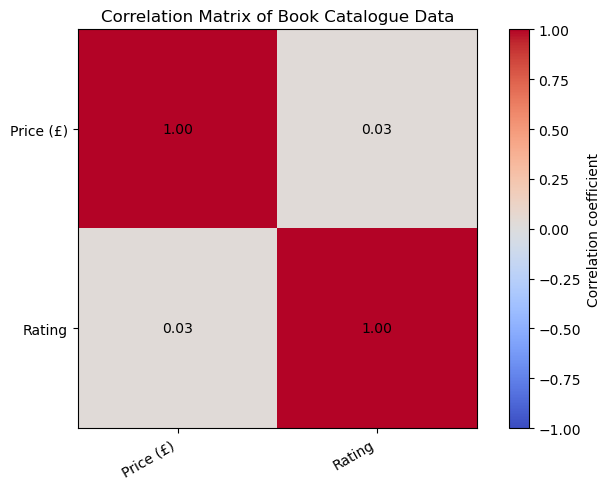

In [29]:
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Book Catalogue Data")
plt.tight_layout()
plt.show()

DO BOOKS WITH HIGHER RATINGS TEND TO HAVE HIGHER PRICES?

count: Number of books with each rating.
mean: Average price for books with that rating.
median: Typical middle price for the group
min and max: Cheapest and most expensive books within the group.

In [30]:
price_by_rating = (
    df.groupby("Rating")["Price (£)"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

price_by_rating

,count,mean,median,min,max
Rating,,,,,
1,226,34.56,34.77,10.40,59.64
2,196,34.81,36.22,10.02,59.95
3,203,34.69,33.78,10.16,59.99
4,179,36.09,37.80,10.01,59.45
5,196,35.37,36.90,10.00,59.92


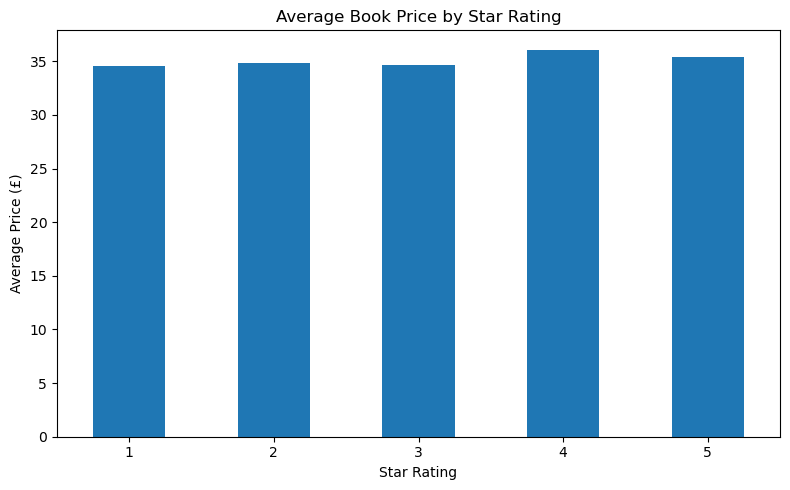

In [31]:
price_by_rating["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Book Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

BOOK AVAILABILITY

In [32]:
availability_summary = (
    df.groupby("Availability")
    .agg(
        Number_of_Books=("Title", "count"),
        Average_Price=("Price (£)", "mean")
    )
    .round(2)
    .sort_values("Number_of_Books", ascending=False)
)

availability_summary

,Number_of_Books,Average_Price
Availability,,
In stock,1000,35.07


PRICE DISTRIBUTION

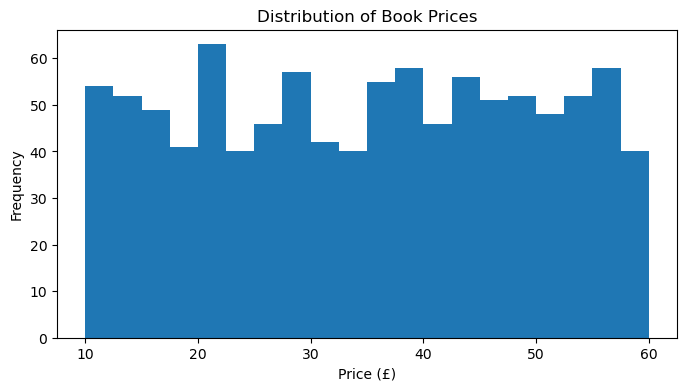

In [35]:
df["Price (£)"].plot.hist(bins=20, figsize=(8, 4))
plt.xlabel("Price (£)")
plt.title("Distribution of Book Prices")
plt.show()

RATING FREQUENCY

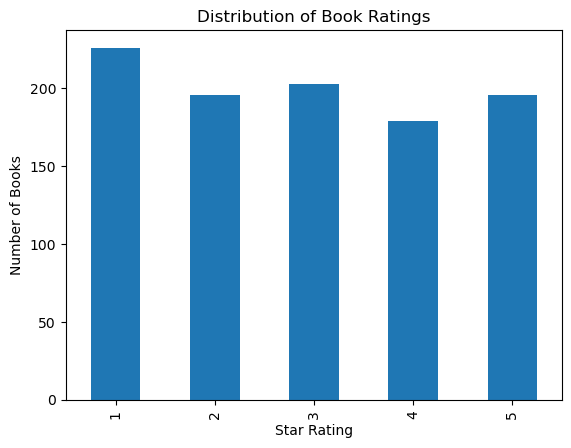

In [36]:
df["Rating"].value_counts().sort_index().plot.bar()
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Ratings")
plt.show()

P